In [1]:
import os
import random
import time
from pathlib import Path
import sys
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

# ---------- konfigurasi ----------
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 10
FREEZE_EPOCHS = 2            # epoch awal: backbone dibekukan
LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4
VALIDATION_SIZE = 0.20
NUM_WORKERS = 4            
RESUME = False               # True = lanjut dari checkpoint terakhir

# ---------- path ----------
PROJECT_DIR = Path("/home/sembiring/machine_learning/00_pr0j3ct/trash-image-classifier")
TRAIN_DIR = PROJECT_DIR / "train"
SUBMISSION_DIR = PROJECT_DIR / "submission"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

BEST_WEIGHTS_PATH = SUBMISSION_DIR / "model.pth"
LAST_CKPT_PATH = CHECKPOINT_DIR / "efficientnet_b0_last.pth"
HISTORY_CSV_PATH = CHECKPOINT_DIR / "efficientnet_b0_history.csv"

SUBMISSION_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device         :", device)
print("PyTorch        :", torch.__version__)
print("CUDA tersedia  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))

/home/sembiring/env/pytorch/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device         : cuda
PyTorch        : 2.13.0+cu132
CUDA tersedia  : True
GPU            : NVIDIA GeForce RTX 4050 Laptop GPU


        kelas  jumlah
botol_plastik     523
gelas_plastik     521
kertas_kardus     365
saset_kemasan     673
    styrofoam     671
Total gambar: 2753
File gagal dibaca: 0


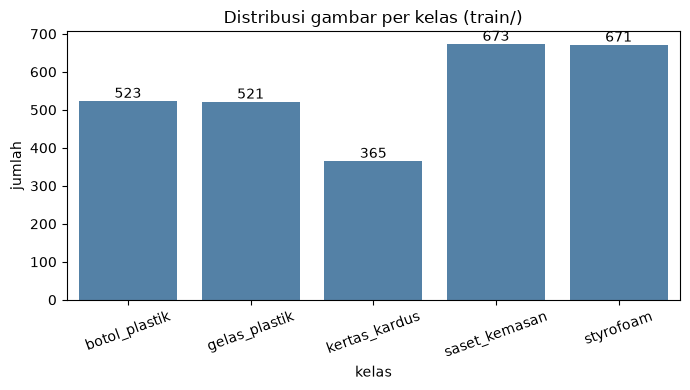

In [2]:
EXPECTED_CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus",
                    "saset_kemasan", "styrofoam"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(f"Folder train tidak ditemukan: {TRAIN_DIR}")

class_dirs = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
if class_dirs != EXPECTED_CLASSES:
    raise ValueError(
        f"Nama folder kelas tidak sesuai.\nDitemukan: {class_dirs}\nDiharapkan: {EXPECTED_CLASSES}"
    )

# hitung jumlah gambar aktual per kelas
counts = {
    c: sum(1 for f in (TRAIN_DIR / c).iterdir() if f.suffix.lower() in IMG_EXT)
    for c in class_dirs
}
df_counts = pd.DataFrame({"kelas": list(counts.keys()), "jumlah": list(counts.values())})
print(df_counts.to_string(index=False))
print("Total gambar:", df_counts["jumlah"].sum())

# cek file yang gagal dibaca (file asli tidak diubah)
rusak = []
for c in class_dirs:
    for f in (TRAIN_DIR / c).iterdir():
        if f.suffix.lower() in IMG_EXT:
            try:
                with Image.open(f) as im:
                    im.verify()
            except Exception as e:
                rusak.append((str(f), repr(e)))
print("File gagal dibaca:", len(rusak))
for p, e in rusak[:10]:
    print("  ", p, e)

# grafik distribusi kelas
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_counts, x="kelas", y="jumlah", color="steelblue")
for container in ax.containers:
    ax.bar_label(container)
plt.title("Distribusi gambar per kelas (train/)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [3]:
# ImageFolder tanpa transform dulu, hanya untuk mengambil label & class_to_idx
base_ds = datasets.ImageFolder(TRAIN_DIR)
class_names = base_ds.classes
class_to_idx = base_ds.class_to_idx
NUM_CLASSES = len(class_names)
print("class_to_idx:", class_to_idx)

targets = np.array(base_ds.targets)
all_idx = np.arange(len(targets))

train_idx, val_idx = train_test_split(
    all_idx,
    test_size=VALIDATION_SIZE,
    stratify=targets,
    random_state=SEED,
)

# pastikan tidak ada yang bocor antar subset
assert len(set(train_idx) & set(val_idx)) == 0, "Ada gambar di train dan val sekaligus"
assert len(train_idx) + len(val_idx) == len(targets)

split_df = pd.DataFrame({
    "kelas": class_names,
    "train": [int((targets[train_idx] == i).sum()) for i in range(NUM_CLASSES)],
    "val": [int((targets[val_idx] == i).sum()) for i in range(NUM_CLASSES)],
})
print(split_df.to_string(index=False))
print("Train:", len(train_idx), "| Val:", len(val_idx))

class_to_idx: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
        kelas  train  val
botol_plastik    418  105
gelas_plastik    417  104
kertas_kardus    292   73
saset_kemasan    538  135
    styrofoam    537  134
Train: 2202 | Val: 551


In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_tfms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# dua ImageFolder dengan transform berbeda, indeks split yang sama
train_full = datasets.ImageFolder(TRAIN_DIR, transform=train_tfms)
val_full = datasets.ImageFolder(TRAIN_DIR, transform=val_tfms)
assert train_full.class_to_idx == val_full.class_to_idx == class_to_idx

train_ds = Subset(train_full, train_idx)
val_ds = Subset(val_full, val_idx)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)

xb, yb = next(iter(train_loader))
print("Batch gambar:", tuple(xb.shape), "| Batch label:", tuple(yb.shape))

Batch gambar: (16, 3, 224, 224) | Batch label: (16,)


In [5]:
def build_model(pretrained):
    """pretrained=True: unduh bobot ImageNet. False: struktur saja (untuk resume / evaluasi)."""
    if pretrained:
        try:
            model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        except Exception as e:
            raise RuntimeError(
                "Gagal memuat pretrained weights EfficientNet-B0. "
                "Cek koneksi internet, lalu jalankan ulang. "
                f"Detail: {e}"
            )
    else:
        model = efficientnet_b0(weights=None)

    in_features = model.classifier[1].in_features   # 1280
    model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
    return model


def set_backbone_trainable(model, trainable):
    for p in model.features.parameters():
        p.requires_grad = trainable


model = build_model(pretrained=not RESUME).to(device)

# cek bentuk output
with torch.no_grad():
    model.eval()
    out = model(xb.to(device))
print("Output model:", tuple(out.shape))   # harus [BATCH_SIZE, 5]
assert out.shape == (xb.shape[0], NUM_CLASSES)

criterion = nn.CrossEntropyLoss()

# dua parameter group dibuat sekali di awal, tidak diganti-ganti per epoch
optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": LEARNING_RATE_BACKBONE},
        {"params": model.classifier.parameters(), "lr": LEARNING_RATE_HEAD},
    ],
    weight_decay=WEIGHT_DECAY,
)

Output model: (16, 5)


In [6]:
def save_atomic(obj, path):
    """Simpan ke file .tmp dulu, lalu ganti file tujuan."""
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def clone_state_dict(m):
    return {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}


def train_one_epoch(model, loader, criterion, optimizer, device, freeze_backbone):
    model.train()
    if freeze_backbone:
        # backbone beku -> BatchNorm-nya juga jangan ikut update statistik
        model.features.eval()

    total_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc="train", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    for images, labels in tqdm(loader, desc="val", leave=False):
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        total += images.size(0)
        all_preds.append(logits.argmax(1).cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average="macro")
    return total_loss / total, acc, macro_f1, preds, labels

In [7]:
history = []
best_f1 = -1.0
best_epoch = 0
best_state = None
last_done_epoch = 0

if RESUME:
    if not LAST_CKPT_PATH.exists():
        raise FileNotFoundError(
            f"RESUME=True tapi checkpoint tidak ada: {LAST_CKPT_PATH}"
        )
    ckpt = torch.load(LAST_CKPT_PATH, map_location=device)

    if ckpt.get("class_to_idx") != class_to_idx:
        raise ValueError("Checkpoint tidak kompatibel: class_to_idx berbeda dengan dataset sekarang.")

    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    last_done_epoch = ckpt["epoch"]
    best_f1 = ckpt["best_val_macro_f1"]
    best_epoch = ckpt["best_epoch"]
    best_state = ckpt["best_model_state_dict"]
    history = ckpt["history"]

    # kalau file submission hilang, buat lagi dari bobot terbaik di checkpoint
    if not BEST_WEIGHTS_PATH.exists():
        save_atomic(best_state, BEST_WEIGHTS_PATH)

    print(f"Resume berhasil: epoch selesai = {last_done_epoch}, "
          f"best Macro-F1 = {best_f1:.4f} (epoch {best_epoch})")
else:
    print("Mulai training dari awal (pretrained ImageNet).")

Mulai training dari awal (pretrained ImageNet).


In [ ]:
config = {
    "seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
    "epochs": EPOCHS, "freeze_epochs": FREEZE_EPOCHS,
    "lr_head": LEARNING_RATE_HEAD, "lr_backbone": LEARNING_RATE_BACKBONE,
    "weight_decay": WEIGHT_DECAY, "val_size": VALIDATION_SIZE,
}

if last_done_epoch >= EPOCHS:
    print(f"Semua {EPOCHS} epoch sudah selesai, training tidak diulang.")
else:
    try:
        for epoch in range(last_done_epoch + 1, EPOCHS + 1):
            t0 = time.time()

            # atur beku/buka backbone sesuai nomor epoch (juga berlaku saat resume)
            freeze = epoch <= FREEZE_EPOCHS
            set_backbone_trainable(model, not freeze)

            tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion,
                                              optimizer, device, freeze)
            va_loss, va_acc, va_f1, _, _ = evaluate(model, val_loader, criterion, device)

            history.append({
                "epoch": epoch,
                "train_loss": float(tr_loss), "train_acc": float(tr_acc),
                "val_loss": float(va_loss), "val_acc": float(va_acc),
                "val_macro_f1": float(va_f1),
            })

            # simpan bobot terbaik (untuk submission) kalau Macro-F1 naik
            improved = va_f1 > best_f1
            if improved:
                best_f1 = float(va_f1)
                best_epoch = epoch
                best_state = clone_state_dict(model)
                save_atomic(best_state, BEST_WEIGHTS_PATH)

            # simpan checkpoint terbaru (untuk resume) di akhir tiap epoch
            save_atomic({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_f1,
                "best_epoch": best_epoch,
                "best_model_state_dict": best_state,
                "history": history,
                "config": config,
                "class_to_idx": class_to_idx,
            }, LAST_CKPT_PATH)

            pd.DataFrame(history).to_csv(HISTORY_CSV_PATH, index=False)

            print(f"Epoch {epoch:02d}/{EPOCHS} "
                  f"[{'frozen' if freeze else 'finetune'}] | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f} F1 {va_f1:.4f}"
                  f"{'  <- best' if improved else ''} | {time.time() - t0:.0f}s")

    except torch.cuda.OutOfMemoryError:
        print("CUDA out of memory. Kecilkan BATCH_SIZE (mis. 8), restart kernel, "
              "lalu jalankan lagi dengan RESUME = True.")
        raise

Epoch 01/10 [frozen] | train loss 0.5842 acc 0.8247 | val loss 0.3157 acc 0.8929 F1 0.8902  <- best | 27s


Epoch 02/10 [frozen] | train loss 0.2818 acc 0.9133 | val loss 0.2476 acc 0.9201 F1 0.9185  <- best | 28s


Epoch 03/10 [finetune] | train loss 0.4455 acc 0.8406 | val loss 0.2150 acc 0.9347 F1 0.9346  <- best | 33s


Epoch 04/10 [finetune] | train loss 0.2314 acc 0.9187 | val loss 0.1721 acc 0.9564 F1 0.9556  <- best | 33s


Epoch 05/10 [finetune] | train loss 0.1466 acc 0.9550 | val loss 0.1414 acc 0.9564 F1 0.9563  <- best | 33s


Epoch 06/10 [finetune] | train loss 0.1310 acc 0.9537 | val loss 0.1762 acc 0.9365 F1 0.9373 | 33s


Epoch 07/10 [finetune] | train loss 0.0950 acc 0.9723 | val loss 0.1431 acc 0.9528 F1 0.9520 | 33s


Epoch 08/10 [finetune] | train loss 0.0930 acc 0.9709 | val loss 0.1486 acc 0.9528 F1 0.9517 | 33s


Epoch 09/10 [finetune] | train loss 0.0661 acc 0.9791 | val loss 0.1559 acc 0.9456 F1 0.9456 | 32s


train:   0%|                                                                                                                         | 0/138 [00:00<?, ?it/s]

In [ ]:
best_model = build_model(pretrained=False).to(device)
best_model.load_state_dict(torch.load(BEST_WEIGHTS_PATH, map_location=device))

val_loss, val_acc, val_f1, val_preds, val_labels = evaluate(
    best_model, val_loader, criterion, device
)
val_prec = precision_score(val_labels, val_preds, average="macro", zero_division=0)
val_rec = recall_score(val_labels, val_preds, average="macro", zero_division=0)

print(f"Best epoch          : {best_epoch}")
print(f"Best val Macro-F1   : {best_f1:.4f}")
print(f"Val accuracy        : {val_acc:.4f}")
print(f"Macro precision     : {val_prec:.4f}")
print(f"Macro recall        : {val_rec:.4f}")
print(f"Val loss            : {val_loss:.4f}\n")
print(classification_report(val_labels, val_preds, target_names=class_names, digits=4))

# confusion matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion matrix (validation lokal)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# kurva training
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="train")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="val")
axes[0].set_title("Loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["val_macro_f1"], marker="o", color="green")
axes[1].set_title("Validation Macro-F1 per epoch")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

hist_df.to_csv(HISTORY_CSV_PATH, index=False)

In [ ]:
salah = np.where(val_preds != val_labels)[0]
print(f"Jumlah salah prediksi: {len(salah)} dari {len(val_labels)}")

n_show = min(12, len(salah))
if n_show > 0:
    rng = np.random.default_rng(SEED)
    pilih = rng.choice(salah, size=n_show, replace=False)

    cols = 4
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(cols * 3.2, rows * 3.4))
    for i, k in enumerate(pilih):
        img_path = val_full.samples[val_idx[k]][0]
        aktual, prediksi = int(val_labels[k]), int(val_preds[k])
        plt.subplot(rows, cols, i + 1)
        plt.imshow(Image.open(img_path).convert("RGB"))
        plt.axis("off")
        plt.title(f"Aktual: {aktual} ({class_names[aktual]})\n"
                  f"Prediksi: {prediksi} ({class_names[prediksi]})", fontsize=8)
    plt.tight_layout()
    plt.show()

In [ ]:
# Pastikan Python mencari model.py di folder submission
sys.path.insert(0, str(SUBMISSION_DIR))

# Import file model.py
import model as submission_model
importlib.reload(submission_model)

# Periksa lokasi file yang berhasil diimpor
print("File model yang digunakan:", submission_model.__file__)

In [ ]:
# 1-2. import dan bangun model tanpa unduh bobot
sub_net = submission_model.get_model()

# 3. muat model.pth
state = torch.load(BEST_WEIGHTS_PATH, map_location="cpu")
sub_net.load_state_dict(state)
sub_net.eval()

# 4. forward pass -> 5 logit
dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE)
with torch.no_grad():
    logits = sub_net(dummy)
print("Output logits:", tuple(logits.shape))
assert logits.shape == (2, 5)

# 5. transform menghasilkan [3, 224, 224]
contoh_path = val_full.samples[val_idx[0]][0]
contoh_img = Image.open(contoh_path).convert("RGB")
t_sub = submission_model.get_transform()(contoh_img)
print("Output transform:", tuple(t_sub.shape))
assert t_sub.shape == (3, IMAGE_SIZE, IMAGE_SIZE)

# konsisten dengan transform validation di notebook
assert torch.allclose(t_sub, val_tfms(contoh_img)), "Transform submission beda dengan notebook"

# 6. urutan kelas
print("Urutan kelas  :", class_to_idx)

# 7. ukuran file
size_mb = BEST_WEIGHTS_PATH.stat().st_size / (1024 ** 2)
print(f"Ukuran model.pth: {size_mb:.1f} MB (batas 500 MB)")
assert size_mb <= 500

print("Pemeriksaan lokal selesai.")

In [ ]:
print("=== RINGKASAN ===")
print(f"Total gambar        : {len(targets)}")
print(split_df.to_string(index=False))
print("\nKonfigurasi:")
for k, v in config.items():
    print(f"  {k}: {v}")
print(f"\nBest epoch          : {best_epoch}")
print(f"Best val Macro-F1   : {best_f1:.4f}")
print(f"Val accuracy        : {val_acc:.4f}")
print(f"Macro precision     : {val_prec:.4f}")
print(f"Macro recall        : {val_rec:.4f}")
print(f"\nBobot submission    : {BEST_WEIGHTS_PATH}")
print(f"Checkpoint training : {LAST_CKPT_PATH}")
print(f"Riwayat metrik      : {HISTORY_CSV_PATH}")
print("\nUntuk melanjutkan training yang terputus: set RESUME = True di cell konfigurasi,")
print("lalu jalankan ulang notebook dari atas (Run All).")
print("Catatan: skor ini dari validation lokal, belum tentu sama dengan hidden validation.")